In [1]:
from pathlib import Path
import pandas as pd
from credit_card_fraud_detection.paths import ROOT, INTERIM
from datetime import date
import matplotlib.pyplot as plt
import seaborn as sns

c:\Users\shank\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
2026-11-17 15:03:44.902 | INFO     | credit_card_fraud_detection.config:<module>:11 - PROJ_ROOT path is: C:\Users\shank\OneDrive\Documents\Data analysis\credit_card_fraud_detection


In [2]:
train = INTERIM / "train_interim.csv"
test = INTERIM / "test_interim.csv"

In [3]:
train_df = pd.read_csv(train)
test_df = pd.read_csv(test)

"High-dollar transactions are where most of our fraud losses occur."

Variables-to-use
* amount_usd
* is_fraud_
* velocity
* merchant_category

In [4]:
q1_cols = ["amount_usd", "is_fraud", "velocity_score", "merchant_category"]
q1_df = train_df[q1_cols]
q1_df.head()

,amount_usd,is_fraud,velocity_score,merchant_category
0,61.16,0.0,5.5,Groceries
1,24.83,0.0,33.4,Online Retail
2,6.36,0.0,35.8,Utilities
3,37.44,0.0,20.7,Groceries
4,653.85,0.0,34.8,Electronics


In [5]:
# group transaction into amount brackets using amount_usd
bins = [0, 50, 200, 1000, float("inf")]
labels = ["$0 - $50", "$50 - $200", "$200 - $1,000", "$1,000+"]
q1_df = (
    q1_df.groupby(pd.cut(q1_df["amount_usd"], bins=bins, labels=labels))["is_fraud"]
    .agg(["sum", "mean"])
    .rename(columns={"sum": "total_fraud", "mean": "fraud_pct"})
    .assign(fraud_pct=lambda x: x["fraud_pct"]*100)
    .reset_index()
)

In [6]:
q1_df.sort_values(by="total_fraud", ascending=False).head()

,amount_usd,total_fraud,fraud_pct
0,$0 - $50,8790.0,1.520183
1,$50 - $200,1466.0,2.179926
2,"$200 - $1,000",1297.0,2.644834
3,"$1,000+",136.0,2.494955


<BarContainer object of 4 artists>

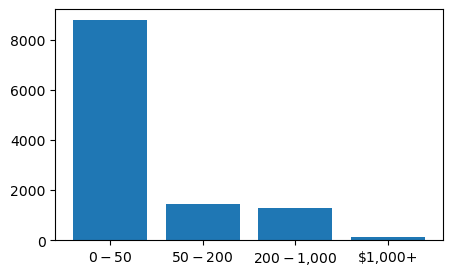

In [7]:
# barplot  to see the difference
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(q1_df["amount_usd"], q1_df["total_fraud"])

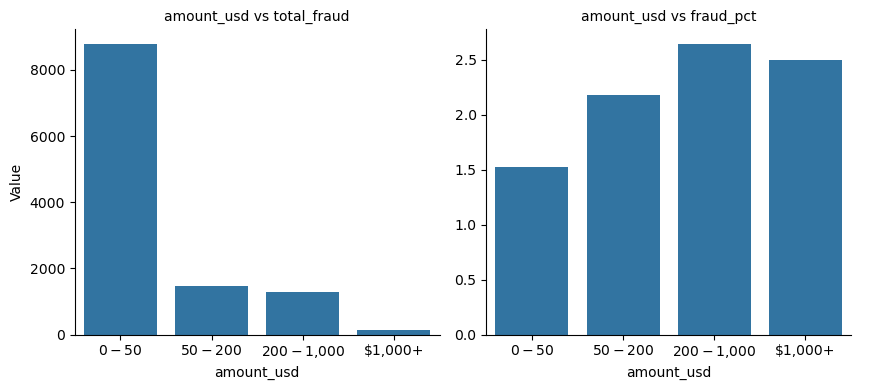

In [8]:
# catplot for multiple bar
# first melt it since we have both required y columns as seperate columns, catplot requires in total 2 columns only X and Y
# melt achieves this
q1_df_long = q1_df.melt(
    id_vars="amount_usd", #to keep fixed or X-axis
    value_vars = ["total_fraud", "fraud_pct"],
    var_name="Group",
    value_name="Value"
)

g = sns.catplot(
    data=q1_df_long,
    x="amount_usd",
    y="Value",
    col="Group",
    kind="bar",
    sharey= False, # make each y-axis have seperate scale and not share amongst each other
    height=4,
    aspect=1.1,
)

g.set_titles("amount_usd vs {col_name}")
g.tight_layout()
plt.show()

<h4>most of the loss is from high frequency low value fraud</h4>

"5+ year accounts are riskier than younger accounts."

Variables-to-use
* card_age_months
* is_fraud

In [9]:
q2_cols = ["card_age_months", "is_fraud"]
q2_df = train_df[q2_cols]
q2_df.head()

,card_age_months,is_fraud
0,48,0.0
1,38,0.0
2,50,0.0
3,48,0.0
4,37,0.0


In [10]:
# group transaction into month brackets using card_age_months
bins = [24, 36, 48, 60, float("inf")]
labels = ["2-3 years", "3-4 years", "4-5 years", "5 years+"]
q2_df = (
    q2_df.groupby(pd.cut(q2_df["card_age_months"], bins=bins, labels=labels))["is_fraud"]
    .agg(["mean"])
    .rename(columns={"mean": "fraud_pct"})
    .assign(fraud_pct=lambda x: x["fraud_pct"]*100)
    .reset_index()
)

<Axes: xlabel='card_age_months', ylabel='fraud_pct'>

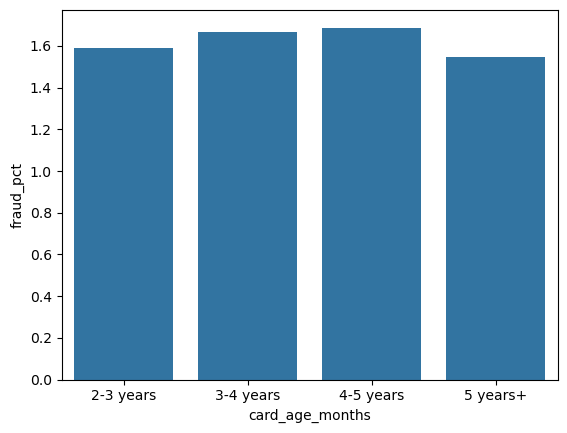

In [11]:
sns.barplot(data=q2_df, x="card_age_months", y="fraud_pct", errorbar=None)

<h4>There seems to be no significant difference between fraud rate with 5+ year old card account versus < 5 year old account </h4>

"International and out-of-state transactions are almost always fraudulent."

Variables-to-use
* is_foreign_transaction
* ip_country_mismatch
* distance_from_home_km
* is_fraud

In [12]:
q3_cols = ["is_foreign_transaction", "ip_country_mismatch", "distance_from_home_km", "is_fraud"]
q3_df = train_df[q3_cols]
q3_df.head()

,is_foreign_transaction,ip_country_mismatch,distance_from_home_km,is_fraud
0,False,False,17.78,0.0
1,False,False,13.06,0.0
2,False,False,8.17,0.0
3,False,False,8.67,0.0
4,False,False,11.69,0.0


In [13]:
# before crosstabl, we will bin distance_from_home_km
bin = [0, 10, 20, 30, 40, 1000]
labels = ['Very near (<10km)', 'close by (10-20km)', 'not that far (20-30km)', 'far (30-40km)', ' very far (40+km)']
q3_df['distance_bins'] = pd.cut(q3_df['distance_from_home_km'], bins=bin, labels=labels, right=False)
q3_df.head()

,is_foreign_transaction,ip_country_mismatch,distance_from_home_km,is_fraud,distance_bins
0,False,False,17.78,0.0,close by (10-20km)
1,False,False,13.06,0.0,close by (10-20km)
2,False,False,8.17,0.0,Very near (<10km)
3,False,False,8.67,0.0,Very near (<10km)
4,False,False,11.69,0.0,close by (10-20km)


In [14]:
#cross tab
rates_ct = pd.crosstab(
    index=[q3_df['is_foreign_transaction'], q3_df['ip_country_mismatch'], q3_df['distance_bins']],
    columns=q3_df['is_fraud'],
    normalize='index'
)

#rename columns
rates_ct = rates_ct.rename(columns={0: 'False_Alarm_Rate', 1: 'Precision_Fraud_Rate'})

#format as percentage
display((rates_ct*100).round(2))

is_fraud                                                           False_Alarm_Rate  \
is_foreign_transaction ip_country_mismatch distance_bins                              
False                  False               Very near (<10km)                  98.66   
                                           close by (10-20km)                 98.65   
                                           not that far (20-30km)             98.63   
                                           far (30-40km)                      98.59   
                                            very far (40+km)                  98.62   
                       True                Very near (<10km)                  88.11   
                                           close by (10-20km)                 88.13   
                                           not that far (20-30km)             86.58   
                                           far (30-40km)                      87.61   
                                            very far (40+km)                  85.38   
True                   False               Very near (<10km)                  92.88   
                                           close by (10-20km)                 92.73   
                                           not that far (20-30km)             93.09   
                                           far (30-40km)                      92.94   
                                            very far (40+km)                  93.84   
                       True                Very near (<10km)                  72.95   
                                           close by (10-20km)                 76.58   
                                           not that far (20-30km)             72.10   
                                           far (30-40km)                      75.77   
                                            very far (40+km)                  75.74   

is_fraud                                                           Precision_Fraud_Rate  
is_foreign_transaction ip_country_mismatch distance_bins                                 
False                  False               Very near (<10km)                       1.34  
                                           close by (10-20km)                      1.35  
                                           not that far (20-30km)                  1.37  
                                           far (30-40km)                           1.41  
                                            very far (40+km)                       1.38  
                       True                Very near (<10km)                      11.89  
                                           close by (10-20km)                     11.87  
                                           not that far (20-30km)                 13.42  
                                           far (30-40km)                          12.39  
                                            very far (40+km)                      14.62  
True                   False               Very near (<10km)                       7.12  
                                           close by (10-20km)                      7.27  
                                           not that far (20-30km)                  6.91  
                                           far (30-40km)                           7.06  
                                            very far (40+km)                       6.16  
                       True                Very near (<10km)                      27.05  
                                           close by (10-20km)                     23.42  
                                           not that far (20-30km)                 27.90  
                                           far (30-40km)                          24.23  
                                            very far (40+km)                      24.26

In [15]:
counts_ct = pd.crosstab(
    index=[q3_df['is_foreign_transaction'], q3_df['ip_country_mismatch'], q3_df['distance_bins']],
    columns=q3_df['is_fraud'],
    margins=True,
    margins_name='Total_Transactions'
)

display(counts_ct)

is_fraud                                                              0.0  \
is_foreign_transaction ip_country_mismatch distance_bins                    
False                  False               Very near (<10km)       328879   
                                           close by (10-20km)      175936   
                                           not that far (20-30km)   90994   
                                           far (30-40km)            49172   
                                            very far (40+km)        25884   
                       True                Very near (<10km)         3342   
                                           close by (10-20km)        1804   
                                           not that far (20-30km)     910   
                                           far (30-40km)              516   
                                            very far (40+km)          257   
True                   False               Very near (<10km)         3900   
                                           close by (10-20km)        2041   
                                           not that far (20-30km)    1092   
                                           far (30-40km)              592   
                                            very far (40+km)          335   
                       True                Very near (<10km)         1281   
                                           close by (10-20km)         713   
                                           not that far (20-30km)     323   
                                           far (30-40km)              197   
                                            very far (40+km)          103   
Total_Transactions                                                 688271   

is_fraud                                                             1.0  \
is_foreign_transaction ip_country_mismatch distance_bins                   
False                  False               Very near (<10km)        4479   
                                           close by (10-20km)       2406   
                                           not that far (20-30km)   1267   
                                           far (30-40km)             701   
                                            very far (40+km)         363   
                       True                Very near (<10km)         451   
                                           close by (10-20km)        243   
                                           not that far (20-30km)    141   
                                           far (30-40km)              73   
                                            very far (40+km)          44   
True                   False               Very near (<10km)         299   
                                           close by (10-20km)        160   
                                           not that far (20-30km)     81   
                                           far (30-40km)              45   
                                            very far (40+km)          22   
                       True                Very near (<10km)         475   
                                           close by (10-20km)        218   
                                           not that far (20-30km)    125   
                                           far (30-40km)              63   
                                            very far (40+km)          33   
Total_Transactions                                                 11689   

is_fraud                                                           Total_Transactions  
is_foreign_transaction ip_country_mismatch distance_bins                               
False                  False               Very near (<10km)                   333358  
                                           close by (10-20km)                  178342  
                                           not that far (20-30km)               92261  
                                       

"Does fraud risk continue to decline steadily as an account matures past the 2-year mark, or does it plateau after a certain point?"

Variables-to-use
* card_age_months
* is_fraud

How to
* plot line graph over months
* run logistic regression against credit_card_age
* Use a segmented regression (or spline model) that allows the relationship to change slope at a specific "knot" (e.g., testing if the slope changes drastically at month 36 or 48).
* if regression coefficient (slope) for the months after your suspected plateau point is not statistically significantly different from zero ($p > 0.05$), you have numerical evidence that the risk is no longer changing with time.


In [16]:
import numpy as np

q4_cols = ["card_age_months", "is_fraud"]
q4_df = train_df[q4_cols]
custom_bins = np.arange(25, 75, 3)

# group transaction into month brackets using card_age_months
q4_df = (
    q4_df.groupby(pd.cut(q4_df["card_age_months"], bins=custom_bins))["is_fraud"]
    .agg(["mean"])
    .rename(columns={"mean": "fraud_pct"})
    .assign(fraud_pct=lambda x: x["fraud_pct"]*100)
    .reset_index()
)
q4_df["card_age_months"] = q4_df["card_age_months"].astype("str")


In [17]:
q4_df

,card_age_months,fraud_pct
0,"(25, 28]",1.442308
1,"(28, 31]",1.687389
2,"(31, 34]",1.639910
3,"(34, 37]",1.572924
4,"(37, 40]",1.690274
5,"(40, 43]",1.620485
6,"(43, 46]",1.668318
7,"(46, 49]",1.761755
8,"(49, 52]",1.577810
9,"(52, 55]",1.714543


<Axes: ylabel='fraud_pct'>

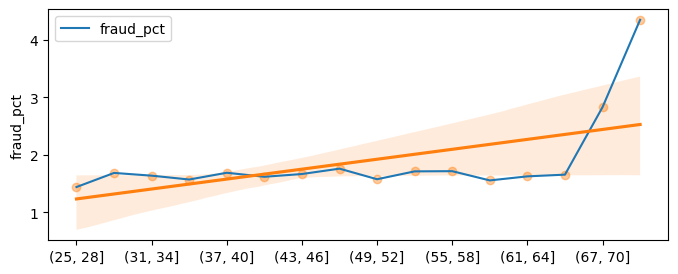

In [18]:
# line plot

q4_df.set_index("card_age_months").plot(figsize=(8,3))
sns.regplot(data=q4_df, x = q4_df.index, y="fraud_pct", scatter_kws={"alpha": 0.4})

In [19]:
import numpy as np

q4_cols = ["card_age_months", "is_fraud"]
q4_df = train_df[q4_cols]
custom_bins = np.arange(25, 60, 3)
custom_bins = np.append(custom_bins, 100)
print(type(custom_bins))

# group transaction into month brackets using card_age_months
q4_df = (
    q4_df.groupby(pd.cut(q4_df["card_age_months"], bins=custom_bins))["is_fraud"]
    .agg(["mean"])
    .rename(columns={"mean": "fraud_pct"})
    .assign(fraud_pct=lambda x: x["fraud_pct"]*100)
    .reset_index()
)
q4_df["card_age_months"] = q4_df["card_age_months"].astype("str")


<class 'numpy.ndarray'>


<Axes: ylabel='fraud_pct'>

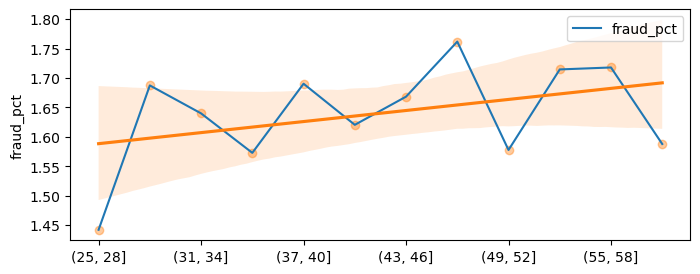

In [20]:
# line plot

q4_df.set_index("card_age_months").plot(figsize=(8,3))
sns.regplot(data=q4_df, x = q4_df.index, y="fraud_pct", scatter_kws={"alpha": 0.4})

In [21]:
# check p values
from scipy import stats

x = q4_df.index 
y = q4_df["fraud_pct"]

slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

print(f"Slope: {slope:.5f}")
print(f"P-value: {p_value:.5f}")

Slope: 0.00939
P-value: 0.20915


To test the hypothesis of a maturity plateau in tenured accounts, a linear regression was fitted to binned fraud rates across card ages ranging from 25 to 60+ months. While a slight upward variation exists, the regression slope yielded a $p$-value of 0.20915, failing to reject the null hypothesis of a zero slope. This confirms that the fraud rate remains statistically stable and flat throughout this lifecycle window, representing a true risk plateau.

In [22]:
#finding baseline
base = train_df["is_fraud"].mean()
rule = train_df["velocity_score"] >= 0.8
flagged = train_df.loc[rule]
precision = flagged["is_fraud"].mean()
coverage = rule.mean()
recall = flagged["is_fraud"].sum() / train_df["is_fraud"].sum()
lift = precision / base
print(f"base={base:.4%} precision={precision:.4%} lift={lift:.1f}x "
      f"coverage={coverage:.3%} recall={recall:.1%}")

base=1.6700% precision=1.7934% lift=1.1x coverage=92.950% recall=99.8%


**coverage** = 92.95%: the rule flags about 93 of every 100 transactions. That’s no use as an alert, since a review team can’t work through that volume. </br>
**recall** = 99.8%: this looks great but is meaningless here. If you flag nearly everything, you catch nearly all the fraud by default. </br>
**precision** = 1.79% vs base = 1.67%, lift = 1.1x: flagged transactions are barely more likely to be fraud than a random transaction. The rule adds almost no information.

In [23]:
train_df["velocity_score"].describe()

count    699960.000000
mean         18.929445
std          10.864385
min           0.000000
25%          11.400000
50%          18.600000
75%          26.000000
max          72.900000
Name: velocity_score, dtype: float64

In [24]:
import pandas as pd

base = train_df["is_fraud"].mean()
total_fraud = train_df["is_fraud"].sum()

rows = []
for q in [0.90, 0.95, 0.99, 0.995]:
    thr = train_df["velocity_score"].quantile(q)
    rule = train_df["velocity_score"] >= thr
    flagged = train_df.loc[rule, "is_fraud"]
    rows.append({
        "quantile": q,
        "threshold": thr,
        "coverage": rule.mean(),                 # share of transactions flagged
        "precision": flagged.mean(),             # fraud rate among flagged
        "lift": flagged.mean() / base,
        "recall": flagged.sum() / total_fraud,   # share of all fraud caught
    })

print(pd.DataFrame(rows).round(4))

   quantile  threshold  coverage  precision    lift  recall
0     0.900       33.1    0.1003     0.0525  3.1409  0.3152
1     0.950       37.4    0.0508     0.0624  3.7367  0.1897
2     0.990       46.1    0.0100     0.0869  5.2042  0.0522
3     0.995       48.9    0.0050     0.0919  5.5028  0.0275


In [25]:
from sklearn.metrics import roc_auc_score, average_precision_score

y, s = train_df["is_fraud"], train_df["velocity_score"]
print("base rate (PR-AUC of random):", y.mean())
print("ROC-AUC:", roc_auc_score(y, s))
print("PR-AUC:", average_precision_score(y, s))

base rate (PR-AUC of random): 0.016699525687182123
ROC-AUC: 0.7107927599976092
PR-AUC: 0.04259530037165453


In [26]:
# set aside 30-50% of the rows at random
train_df_copy = train_df.copy()
explore = train_df_copy.sample(frac=0.6, random_state=0)
confirm = train_df_copy.drop(explore.index)

In [27]:
# what is the base rate or typical value
explore["is_fraud"].agg(["mean", "sum", "count"])

mean          0.016594
sum        6969.000000
count    419976.000000
Name: is_fraud, dtype: float64

<Axes: xlabel='card_age_months'>

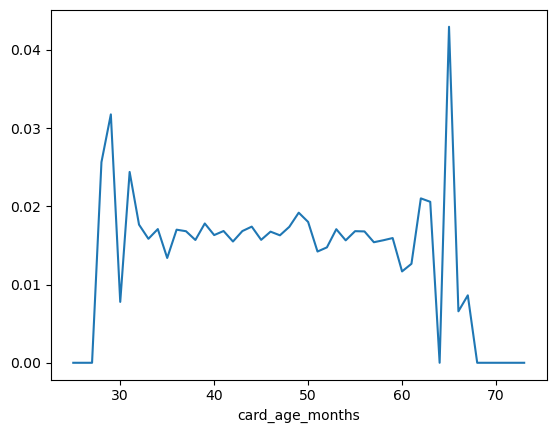

In [28]:
# is the outcome stable over time
rate = explore.groupby("card_age_months")["is_fraud"].mean()
rate = rate.reindex(range(int(rate.index.min()), int(rate.index.max()) + 1))
rate.plot()

In [29]:
train_df.columns

Index(['Unnamed: 0', 'id', 'amount_usd', 'hours_since_last_txn',
       'txn_count_last_24h', 'distance_from_home_km', 'card_age_months',
       'customer_age', 'account_balance_usd', 'cvv_retry_count',
       'velocity_score', 'time_of_day_hour', 'day_of_week',
       'merchant_risk_score', 'prior_disputes', 'merchant_category',
       'card_type', 'auth_method', 'channel', 'device_type',
       'is_foreign_transaction', 'is_new_merchant', 'used_vpn',
       'ip_country_mismatch', 'billing_shipping_mismatch',
       'is_ai_generated_scam_attempt', 'is_fraud'],
      dtype='str')

<Axes: xlabel='id_bin'>

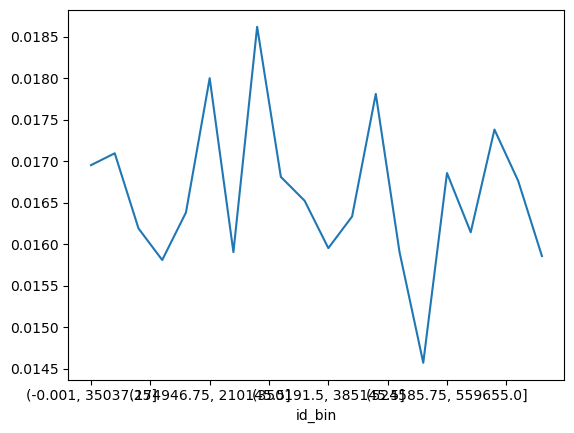

In [30]:
explore = explore.sort_values("id")
explore["id_bin"] = pd.qcut(explore["id"], q=20, duplicates="drop")
explore.groupby("id_bin", observed=True)["is_fraud"].mean().plot()

In [31]:
# read 10 fraud and 10 non fraud 
explore[explore["is_fraud"] == 1].sample(10, random_state=1)

,Unnamed: 0,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,...,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud,id_bin
534861,534861,534861,9.99,6.95,4,36.81,43,62,805.65,0,...,Online,Android Phone,False,False,False,True,False,False,1.0,"(524585.75, 559655.0]"
526365,526365,526365,29.53,7.59,5,17.78,36,79,3302.22,0,...,Online,iPhone,False,True,False,True,False,False,1.0,"(524585.75, 559655.0]"
521614,521614,521614,11.08,3.63,1,8.60,43,63,1266.08,0,...,Contactless,iPhone,False,True,True,True,False,False,1.0,"(489686.5, 524585.75]"
269777,269777,269777,17.42,1.07,3,0.58,47,54,3562.48,1,...,In-App,Windows PC,False,False,False,False,False,False,1.0,"(245224.5, 280383.0]"
621815,621815,621815,9.51,1.80,3,3.37,54,42,532.47,0,...,Online,POS Terminal,False,False,True,True,False,False,1.0,"(594714.75, 629806.5]"
492491,492491,492491,13.26,0.77,5,5.67,61,77,992.68,2,...,Online,Windows PC,False,False,False,False,False,False,1.0,"(489686.5, 524585.75]"
24200,24200,24200,24.55,1.58,3,0.38,48,79,953.24,1,...,Online,Tablet,False,True,False,False,False,False,1.0,"(-0.001, 35037.25]"
593245,593245,593245,527.87,9.59,2,27.76,62,67,843.27,1,...,POS,Tablet,False,True,False,False,False,False,1.0,"(559655.0, 594714.75]"
312900,312900,312900,19.31,3.60,4,7.59,49,55,1428.00,0,...,Contactless,Mac,False,True,False,False,False,False,1.0,"(280383.0, 315366.5]"
631644,631644,631644,33.10,10.84,3,20.92,44,52,865.80,1,...,Online,iPhone,False,False,False,False,False,False,1.0,"(629806.5, 664765.25]"


In [32]:
# non fraud rows
explore[explore["is_fraud"] == 0].sample(10, random_state=1)

,Unnamed: 0,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,...,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud,id_bin
49453,49453,49453,19.49,1.73,2,19.45,57,57,4923.79,0,...,POS,Smart Watch,False,False,False,False,False,False,0.0,"(35037.25, 70400.5]"
393373,393373,393373,4335.14,15.03,5,32.62,55,59,2787.85,0,...,Online,POS Terminal,False,False,False,False,False,False,0.0,"(385145.5, 420110.0]"
139553,139553,139553,43.83,5.56,2,1.73,45,28,571.38,1,...,Contactless,iPhone,True,True,False,False,False,False,0.0,"(105414.25, 140243.0]"
269193,269193,269193,70.38,3.77,1,4.38,46,21,1690.07,0,...,Online,Android Phone,False,False,False,False,False,False,0.0,"(245224.5, 280383.0]"
633548,633548,633548,44.79,1.47,3,19.72,43,58,593.00,0,...,POS,iPhone,False,True,False,False,False,False,0.0,"(629806.5, 664765.25]"
646073,646073,646073,653.30,2.05,3,2.87,44,35,3601.57,0,...,Online,Mac,False,False,False,False,False,False,0.0,"(629806.5, 664765.25]"
624357,624357,624357,14.72,6.13,3,9.24,44,34,624.54,0,...,In-App,Android Phone,False,False,False,False,False,False,0.0,"(594714.75, 629806.5]"
636299,636299,636299,15.37,3.35,2,18.13,51,69,8079.06,0,...,Online,POS Terminal,False,False,False,False,False,False,0.0,"(629806.5, 664765.25]"
654534,654534,654534,31.43,0.47,2,2.40,45,31,2106.21,0,...,In-App,POS Terminal,False,False,False,False,False,False,0.0,"(629806.5, 664765.25]"
72544,72544,72544,11.08,0.47,4,0.16,49,29,2526.24,0,...,POS,Android Phone,False,False,False,False,False,False,0.0,"(70400.5, 105414.25]"


## Distance vs Fraud

In [36]:
# distance of card vs fraud
bands = pd.cut(explore["distance_from_home_km"], [0, 10, 20, 30, 40, 50, 60, 1000],
               labels=["0-10", "10-20", "20-30", "30-40", "40-50", "50-60", "60+"])
explore.groupby(bands)["is_fraud"].agg(["mean", "count"])

,mean,count
distance_from_home_km,,
0-10,0.016481,206297
10-20,0.016311,109805
20-30,0.016973,56915
30-40,0.017289,30713
40-50,0.017537,14826
50-60,0.014904,1409


## Card Age vs Fraud

In [38]:
# distance of card vs fraud
bands = pd.cut(explore["card_age_months"], [20, 30, 40, 50, 60, 1000],
               labels=["20-30", "30-40", "40-50", "50-60", "60+"])
explore.groupby(bands)["is_fraud"].agg(["mean", "count"])

,mean,count
card_age_months,,
20-30,0.015686,510
30-40,0.016637,51393
40-50,0.017022,261719
50-60,0.015538,102713
60+,0.015106,3641


## Card Holder Age vs Fraud

In [40]:
# distance of card vs fraud
bands = pd.cut(explore["customer_age"], [18, 28, 38, 48, 58, 68, 100],
               labels=["18-28", "28-38", "38-48", "48-58", "58-68", "60+"])
explore.groupby(bands)["is_fraud"].agg(["mean", "count"])

,mean,count
customer_age,,
18-28,0.005146,59469
28-38,0.009622,45521
38-48,0.015135,73075
48-58,0.017275,77048
58-68,0.018067,74279
60+,0.027915,87373


## Transaction Amount vs Fraud

In [48]:
# distance of card vs fraud
bands = pd.cut(explore["amount_usd"], [0, 100, 250, 500, 1000, 10000],
               labels=["0-100", "100-250", "250-500", "500-1000","1000+"])
explore.groupby(bands)["is_fraud"].agg(["mean", "count"])

,mean,count
amount_usd,,
0-100,0.015292,379145
100-250,0.038328,9497
250-500,0.029338,6817
500-1000,0.025297,21228
1000+,0.021283,3289


## Balance Amount vs Fraud

In [57]:
# distance of card vs fraud
bands = pd.cut(explore["account_balance_usd"], [0, 500, 750, 1000, 1500, 2000, 2500, 5000, 100000000],
               labels=["0-250","500-750", "750-1000", "1000-1500", "1500-2000", "2000-2500", "2500-5000", "5000+"])
explore.groupby(bands)["is_fraud"].agg(["mean", "count"])

,mean,count
account_balance_usd,,
0-250,0.017720,14560
500-750,0.015589,69342
750-1000,0.015711,62504
1000-1500,0.016535,82070
1500-2000,0.017253,50019
2000-2500,0.016100,36150
2500-5000,0.017474,87502
5000+,0.017780,17829
